<h1 align ='center' style='color:white'>Credit Risk Modelling Project</h1>

<h3 align ='center' style='color:yellow'>Data Collection and Cleaning</h3>

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

pd.set_option('display.float_format', lambda x: '{:.2f}'.format(x))
np.set_printoptions(suppress=True)


In [73]:
df_customers = pd.read_csv('customers.csv')
df_loans = pd.read_csv('loans.csv')
df_bureau = pd.read_csv('bureau_data.csv')

In [74]:
df_customers.shape, df_loans.shape, df_bureau.shape

((50000, 12), (50000, 15), (50000, 8))

In [75]:
df = pd.merge(df_customers, df_loans, on='cust_id')
df.head()

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2467000,49340.00,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,3883000,77660.00,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,...,2170000,43400.00,390600,1736000,21,1562399,1476042,2019-07-24,2019-08-21,False
3,C00004,55,F,Single,Self-Employed,3547000,1,Owned,15,Bangalore,...,1747000,34940.00,314460,1397600,6,1257839,1031094,2019-07-24,2019-08-09,False
4,C00005,37,M,Married,Salaried,3432000,3,Owned,28,Pune,...,4520000,90400.00,813600,3616000,28,1772334,1032458,2019-07-24,2019-08-02,False


In [76]:
df = pd.merge(df, df_bureau)
df.head()

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,default,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2019-07-24,2019-08-10,False,1,1,42,0,0,3,7
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,2019-07-24,2019-08-15,False,3,1,96,12,60,5,4
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,...,2019-07-24,2019-08-21,False,2,1,82,24,147,6,58
3,C00004,55,F,Single,Self-Employed,3547000,1,Owned,15,Bangalore,...,2019-07-24,2019-08-09,False,3,0,115,15,87,5,26
4,C00005,37,M,Married,Salaried,3432000,3,Owned,28,Pune,...,2019-07-24,2019-08-02,False,4,2,120,0,0,5,10


In [77]:
df['default'] = df['default'].astype(int)
df.default.value_counts()

default
0    45703
1     4297
Name: count, dtype: int64

In [78]:
X = df.drop('default', axis=1)
y = df['default']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

In [79]:
df_train = pd.concat([X_train, y_train], axis=1)
df_test = pd.concat([X_test, y_test], axis=1)

df_train.head()

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
12746,C12747,59,M,Married,Self-Employed,11327000,3,Owned,30,Hyderabad,...,2020-10-31,2020-11-11,4,2,152,20,118,4,36,0
32495,C32496,44,F,Single,Salaried,715000,0,Owned,27,Mumbai,...,2022-10-22,2022-10-27,3,1,160,10,62,5,5,0
43675,C43676,38,M,Single,Salaried,3195000,0,Mortgage,26,Chennai,...,2023-12-04,2023-12-29,1,1,54,12,67,4,0,0
9040,C09041,42,M,Married,Salaried,1500000,2,Mortgage,30,Bangalore,...,2020-06-18,2020-07-07,3,0,76,0,0,8,87,0
13077,C13078,58,M,Married,Self-Employed,1817000,4,Owned,29,Pune,...,2020-11-12,2020-12-07,1,2,60,0,0,1,71,0


In [80]:
df_train.isna().sum()

cust_id                         0
age                             0
gender                          0
marital_status                  0
employment_status               0
income                          0
number_of_dependants            0
residence_type                 47
years_at_current_address        0
city                            0
state                           0
zipcode                         0
loan_id                         0
loan_purpose                    0
loan_type                       0
sanction_amount                 0
loan_amount                     0
processing_fee                  0
gst                             0
net_disbursement                0
loan_tenure_months              0
principal_outstanding           0
bank_balance_at_application     0
disbursal_date                  0
installment_start_dt            0
number_of_open_accounts         0
number_of_closed_accounts       0
total_loan_months               0
delinquent_months               0
total_dpd     

In [81]:
df_train.residence_type.unique()

array(['Owned', 'Mortgage', 'Rented', nan], dtype=object)

In [82]:
mode_residence = df_train.residence_type.mode()[0]
mode_residence

'Owned'

In [83]:
df_train.residence_type = df_train.residence_type.fillna(mode_residence)

In [84]:
df_train.residence_type.unique()

array(['Owned', 'Mortgage', 'Rented'], dtype=object)

In [85]:
df_train.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default'],
      dtype='object')

In [86]:
columns_continuous = ['age', 'income', 'number_of_dependants', 'years_at_current_address',
                      'sanction_amount', 'loan_amount', 'processing_fee', 'gst', 'net_disbursement',
                      'loan_tenure_months', 'principal_outstanding', 'bank_balance_at_application',
                      'number_of_open_accounts', 'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
                      'total_dpd', 'enquiry_count', 'credit_utilization_ratio']


columns_categorical = ['gender', 'marital_status', 'employment_status', 'residence_type', 'city',
                       'state', 'zipcode', 'loan_purpose', 'loan_type', 'default']


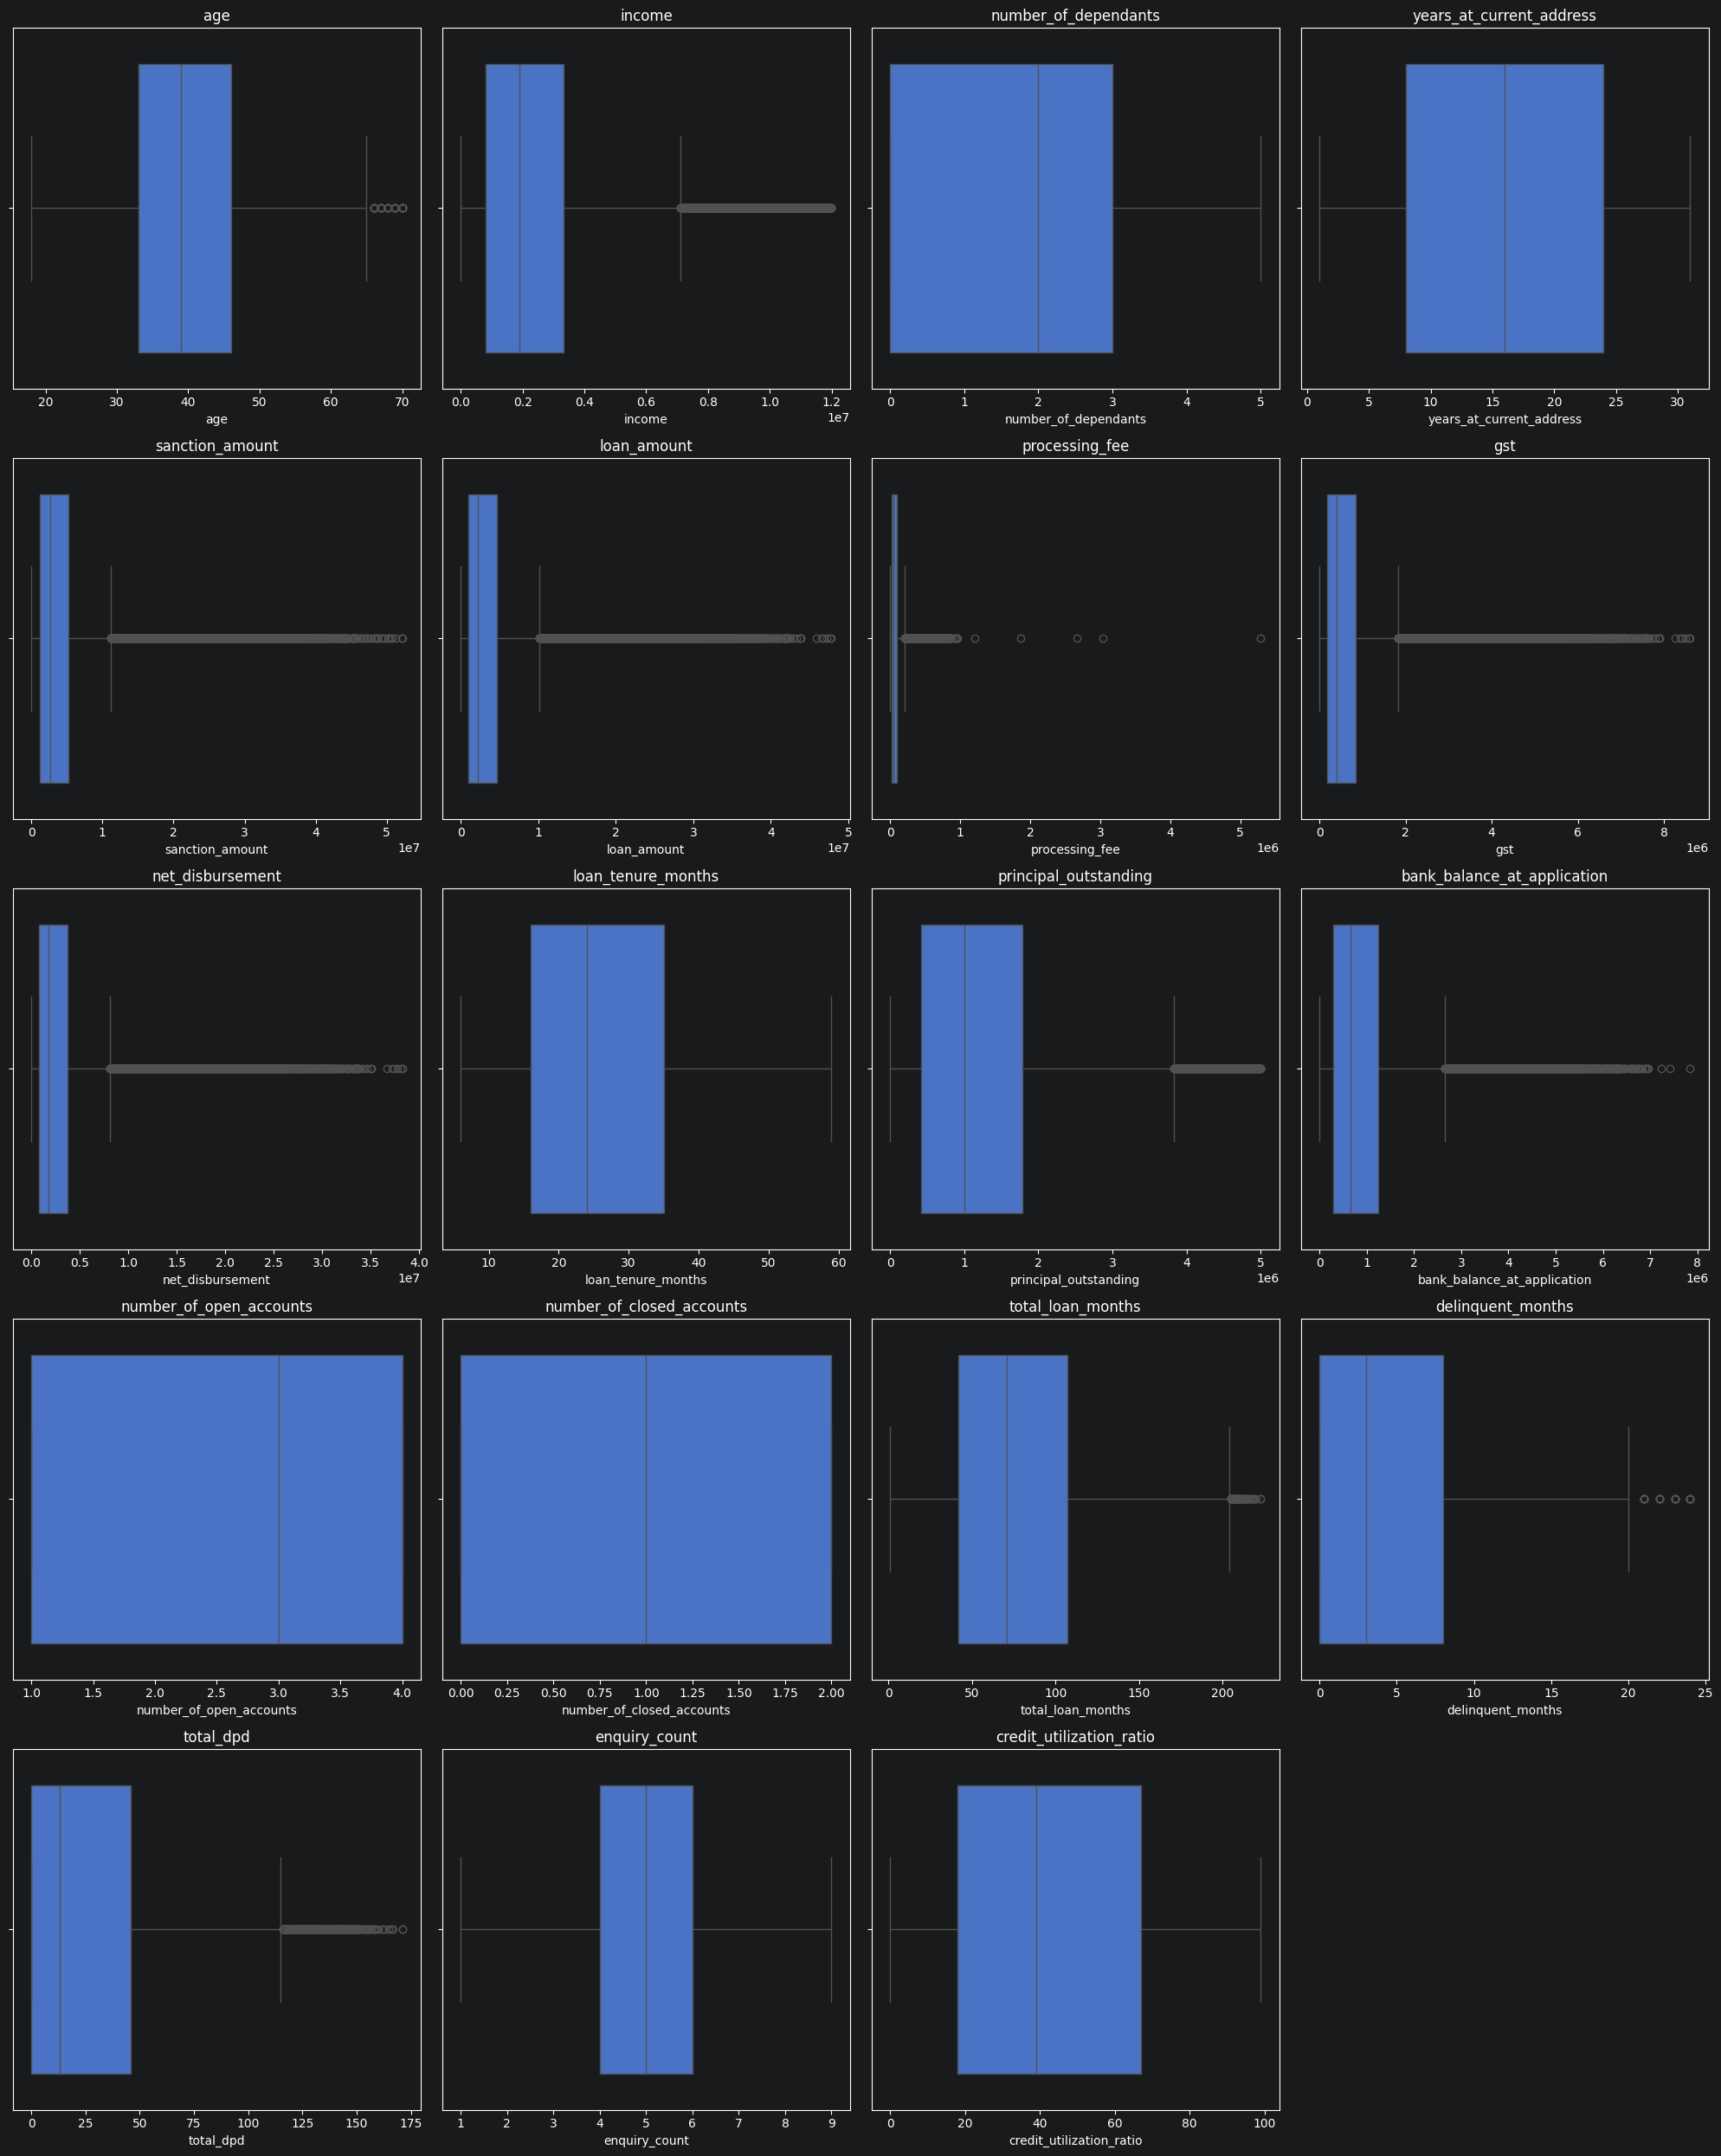

In [87]:
num_plots = len(columns_continuous)
num_cols = 4 # Number of plots per row
num_rows = (num_plots + num_cols - 1) // num_cols # Calculate the number of rows needed

fig, axes = plt.subplots(num_rows, num_cols, figsize=(5 * num_cols, 5 * num_rows)) # Adj
axes = axes.flatten() # Flatten the axes array for easier indexing

for i, col in enumerate(columns_continuous):
    sns.boxplot(x=df_train[col], ax=axes[i])
    axes[i].set_title(col) # Set the title to the name of the variable

# If there are any empty plots (if the number of plots isn't a perfect multiple of num_co
for j in range(i + 1, num_rows * num_cols):
    axes[j].axis('off')

plt.tight_layout()
plt.show()


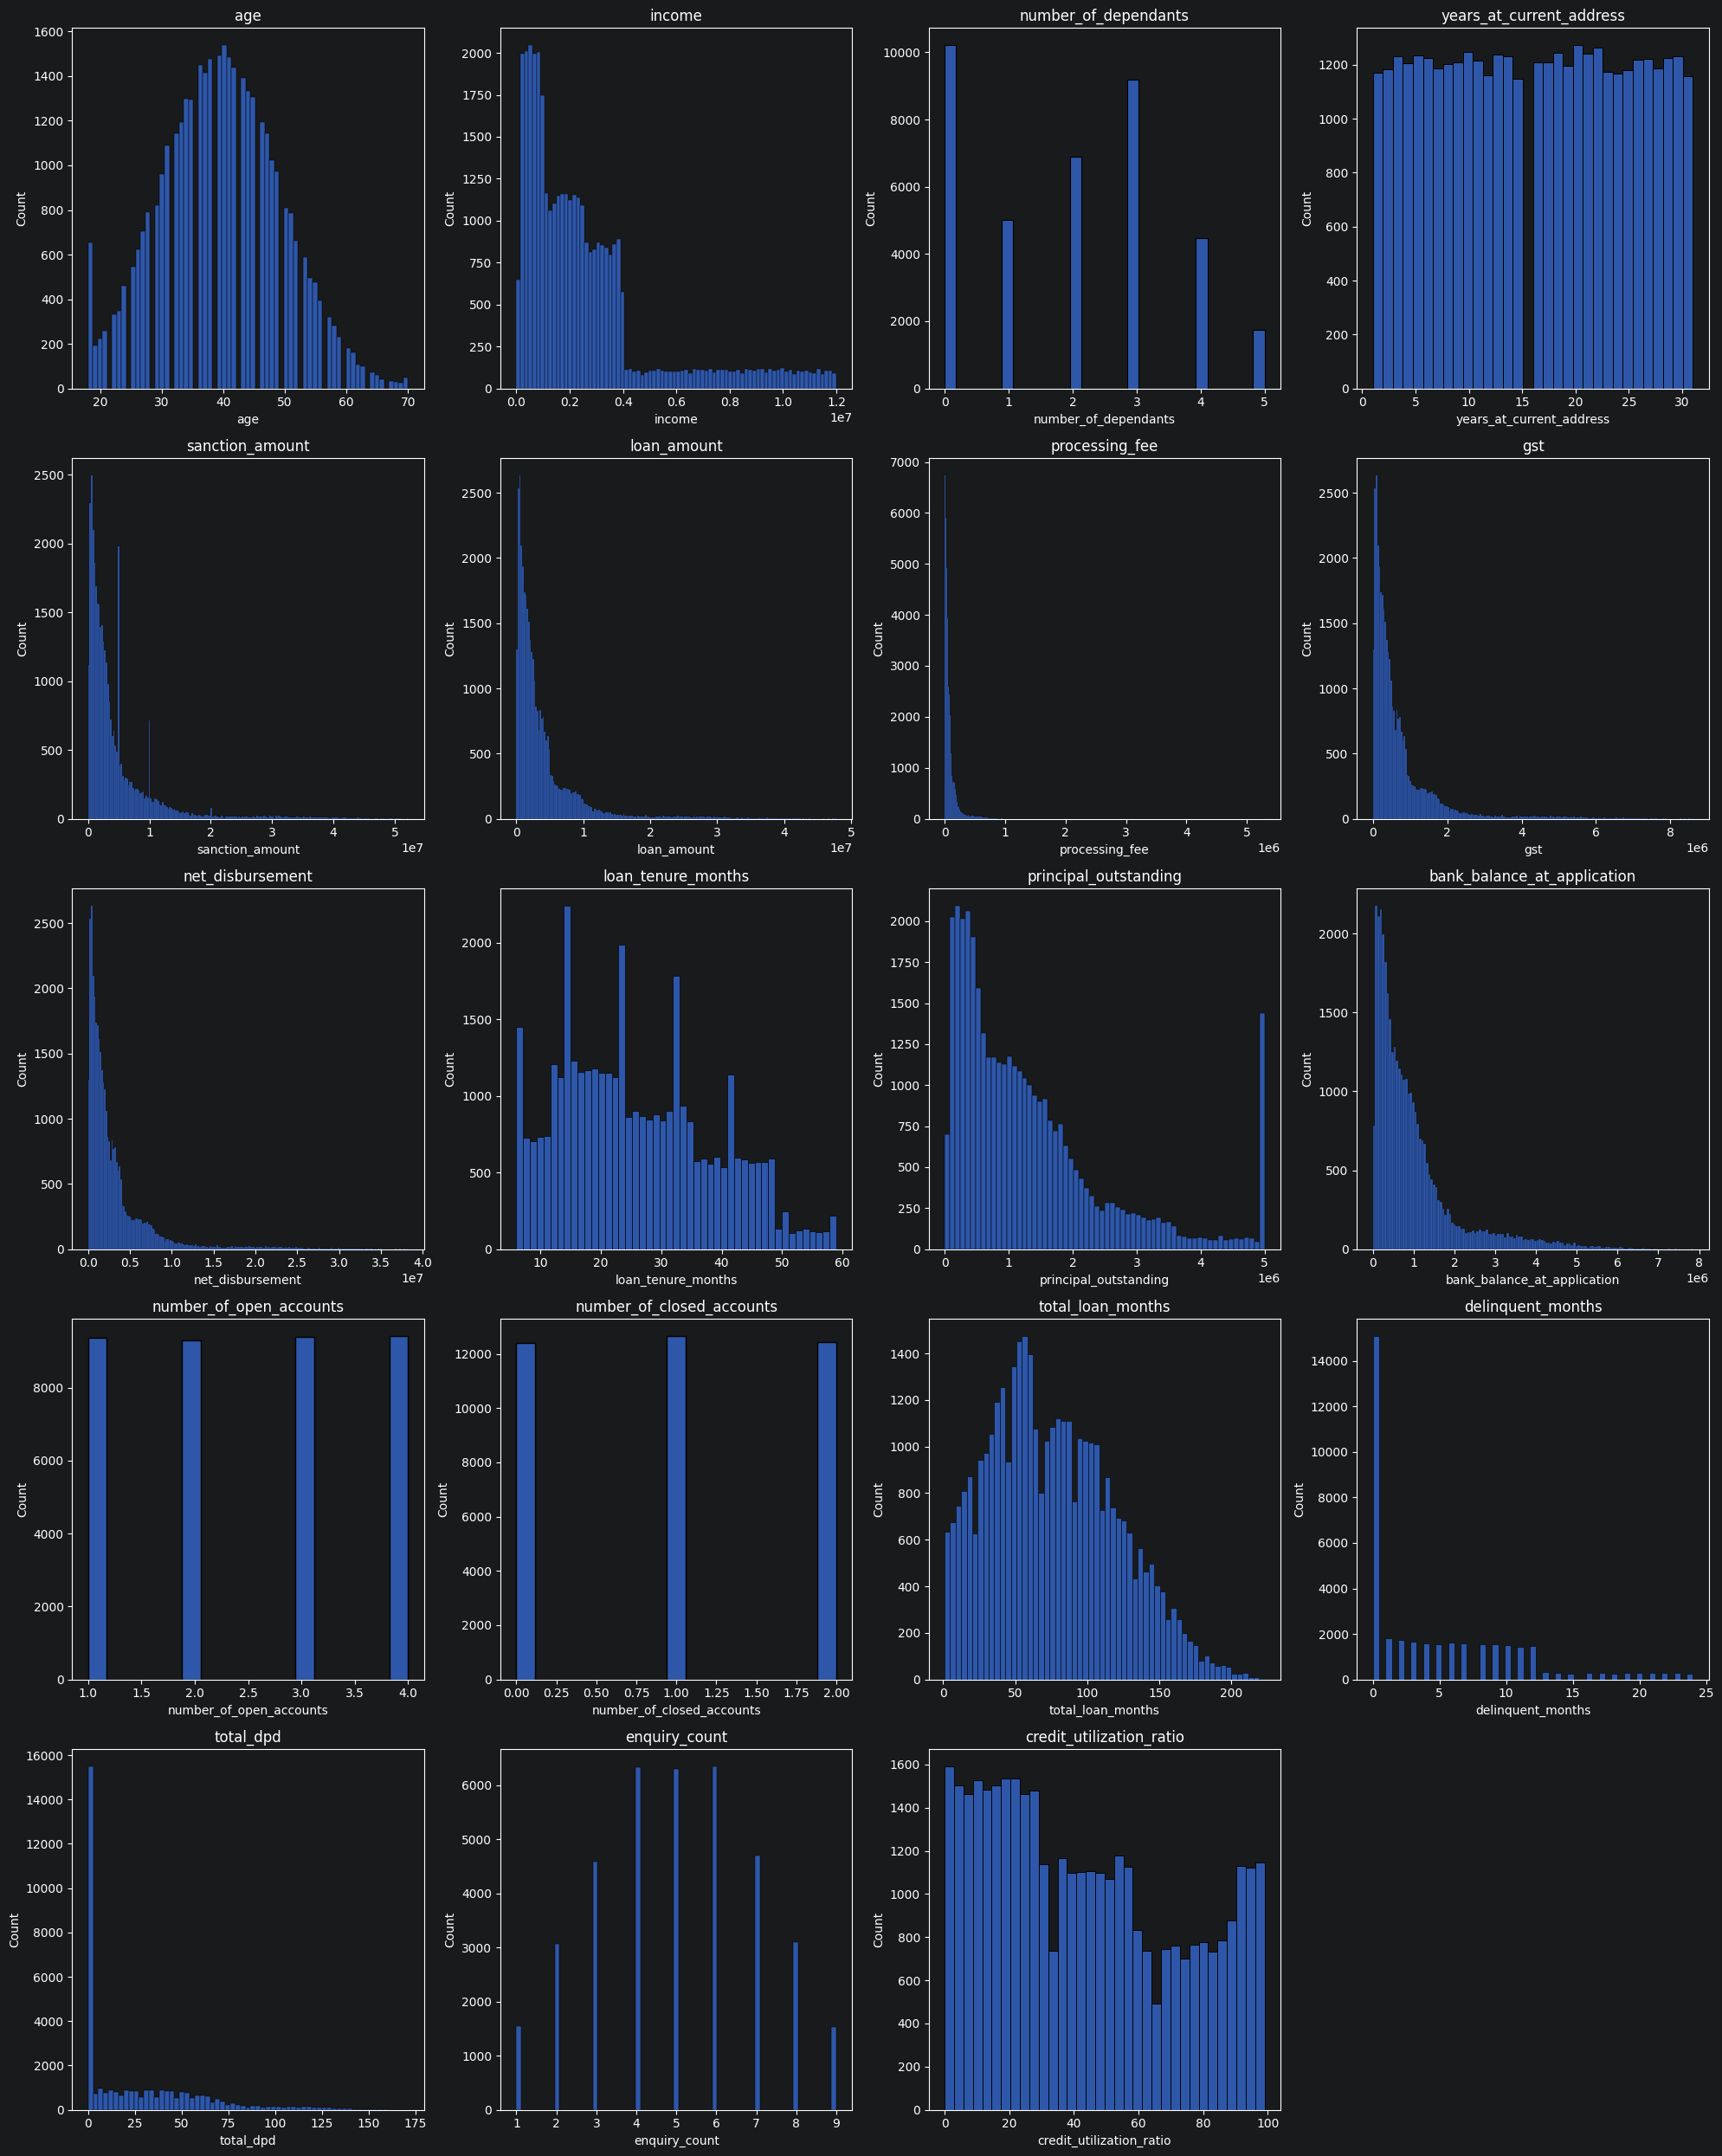

In [88]:
num_plots = len(columns_continuous)
num_cols = 4 # Number of plots per row
num_rows = (num_plots + num_cols - 1) // num_cols # Calculate the number of rows needed

fig, axes = plt.subplots(num_rows, num_cols, figsize=(5 * num_cols, 5 * num_rows)) # Adj
axes = axes.flatten() # Flatten the axes array for easier indexing

for i, col in enumerate(columns_continuous):
    sns.histplot(x=df_train[col], ax=axes[i])
    axes[i].set_title(col) # Set the title to the name of the variable

# If there are any empty plots (if the number of plots isn't a perfect multiple of num_co
for j in range(i + 1, num_rows * num_cols):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [89]:
df_train.processing_fee.describe()

count     37500.00
mean      80290.68
std      113128.14
min           0.00
25%       19220.00
50%       44600.00
75%       92420.00
max     5293543.52
Name: processing_fee, dtype: float64

In [90]:
df_train[(df_train.processing_fee/df_train.loan_amount)>0.03][['loan_amount', 'processing_fee']]

,loan_amount,processing_fee
23981,2234000,2669791.02
28174,966000,1214492.67
47089,1738000,1858964.77
29305,2616000,3036378.01
9898,3626000,5293543.52


In [91]:
df_train_1 = df_train[(df_train.processing_fee/df_train.loan_amount)<0.03].copy()
df_train_1[(df_train_1.processing_fee/df_train_1.loan_amount)>0.03][['loan_amount', 'processing_fee']]

,loan_amount,processing_fee


In [92]:
df_test = df_test[(df_test.processing_fee/df_test.loan_amount)<0.03].copy()
df_test.shape

(12497, 33)

In [93]:
for col in columns_categorical:
    print(col, "-->", df_train_1[col].unique())

gender --> ['M' 'F']
marital_status --> ['Married' 'Single']
employment_status --> ['Self-Employed' 'Salaried']
residence_type --> ['Owned' 'Mortgage' 'Rented']
city --> ['Hyderabad' 'Mumbai' 'Chennai' 'Bangalore' 'Pune' 'Kolkata' 'Ahmedabad'
 'Delhi' 'Lucknow' 'Jaipur']
state --> ['Telangana' 'Maharashtra' 'Tamil Nadu' 'Karnataka' 'West Bengal'
 'Gujarat' 'Delhi' 'Uttar Pradesh' 'Rajasthan']
zipcode --> [500001 400001 600001 560001 411001 700001 380001 110001 226001 302001]
loan_purpose --> ['Home' 'Education' 'Personal' 'Auto' 'Personaal']
loan_type --> ['Secured' 'Unsecured']
default --> [0 1]


In [94]:
df_train_1['loan_purpose'] = df_train_1['loan_purpose'].replace('Personaal', 'Personal')
df_test['loan_purpose'] = df_test['loan_purpose'].replace('Personaal', 'Personal')

<h3 align ='center' style='color:yellow'>Exploratory Data Analysis</h3>

In [95]:
columns_continuous

['age',
 'income',
 'number_of_dependants',
 'years_at_current_address',
 'sanction_amount',
 'loan_amount',
 'processing_fee',
 'gst',
 'net_disbursement',
 'loan_tenure_months',
 'principal_outstanding',
 'bank_balance_at_application',
 'number_of_open_accounts',
 'number_of_closed_accounts',
 'total_loan_months',
 'delinquent_months',
 'total_dpd',
 'enquiry_count',
 'credit_utilization_ratio']

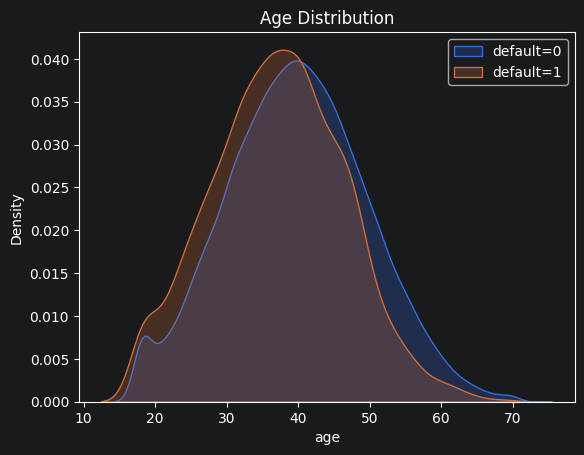

In [96]:
sns.kdeplot(df_train_1['age'][df_train_1['default']==0], fill=True, label='default=0')
sns.kdeplot(df_train_1['age'][df_train_1['default']==1], fill=True, label='default=1')
plt.title('Age Distribution')
plt.legend()
plt.xlabel('age')
plt.show()

Insights:-
1. Orange graph is little bit shifted to the left of blue graph which indicates that people with young age are more likely to default.

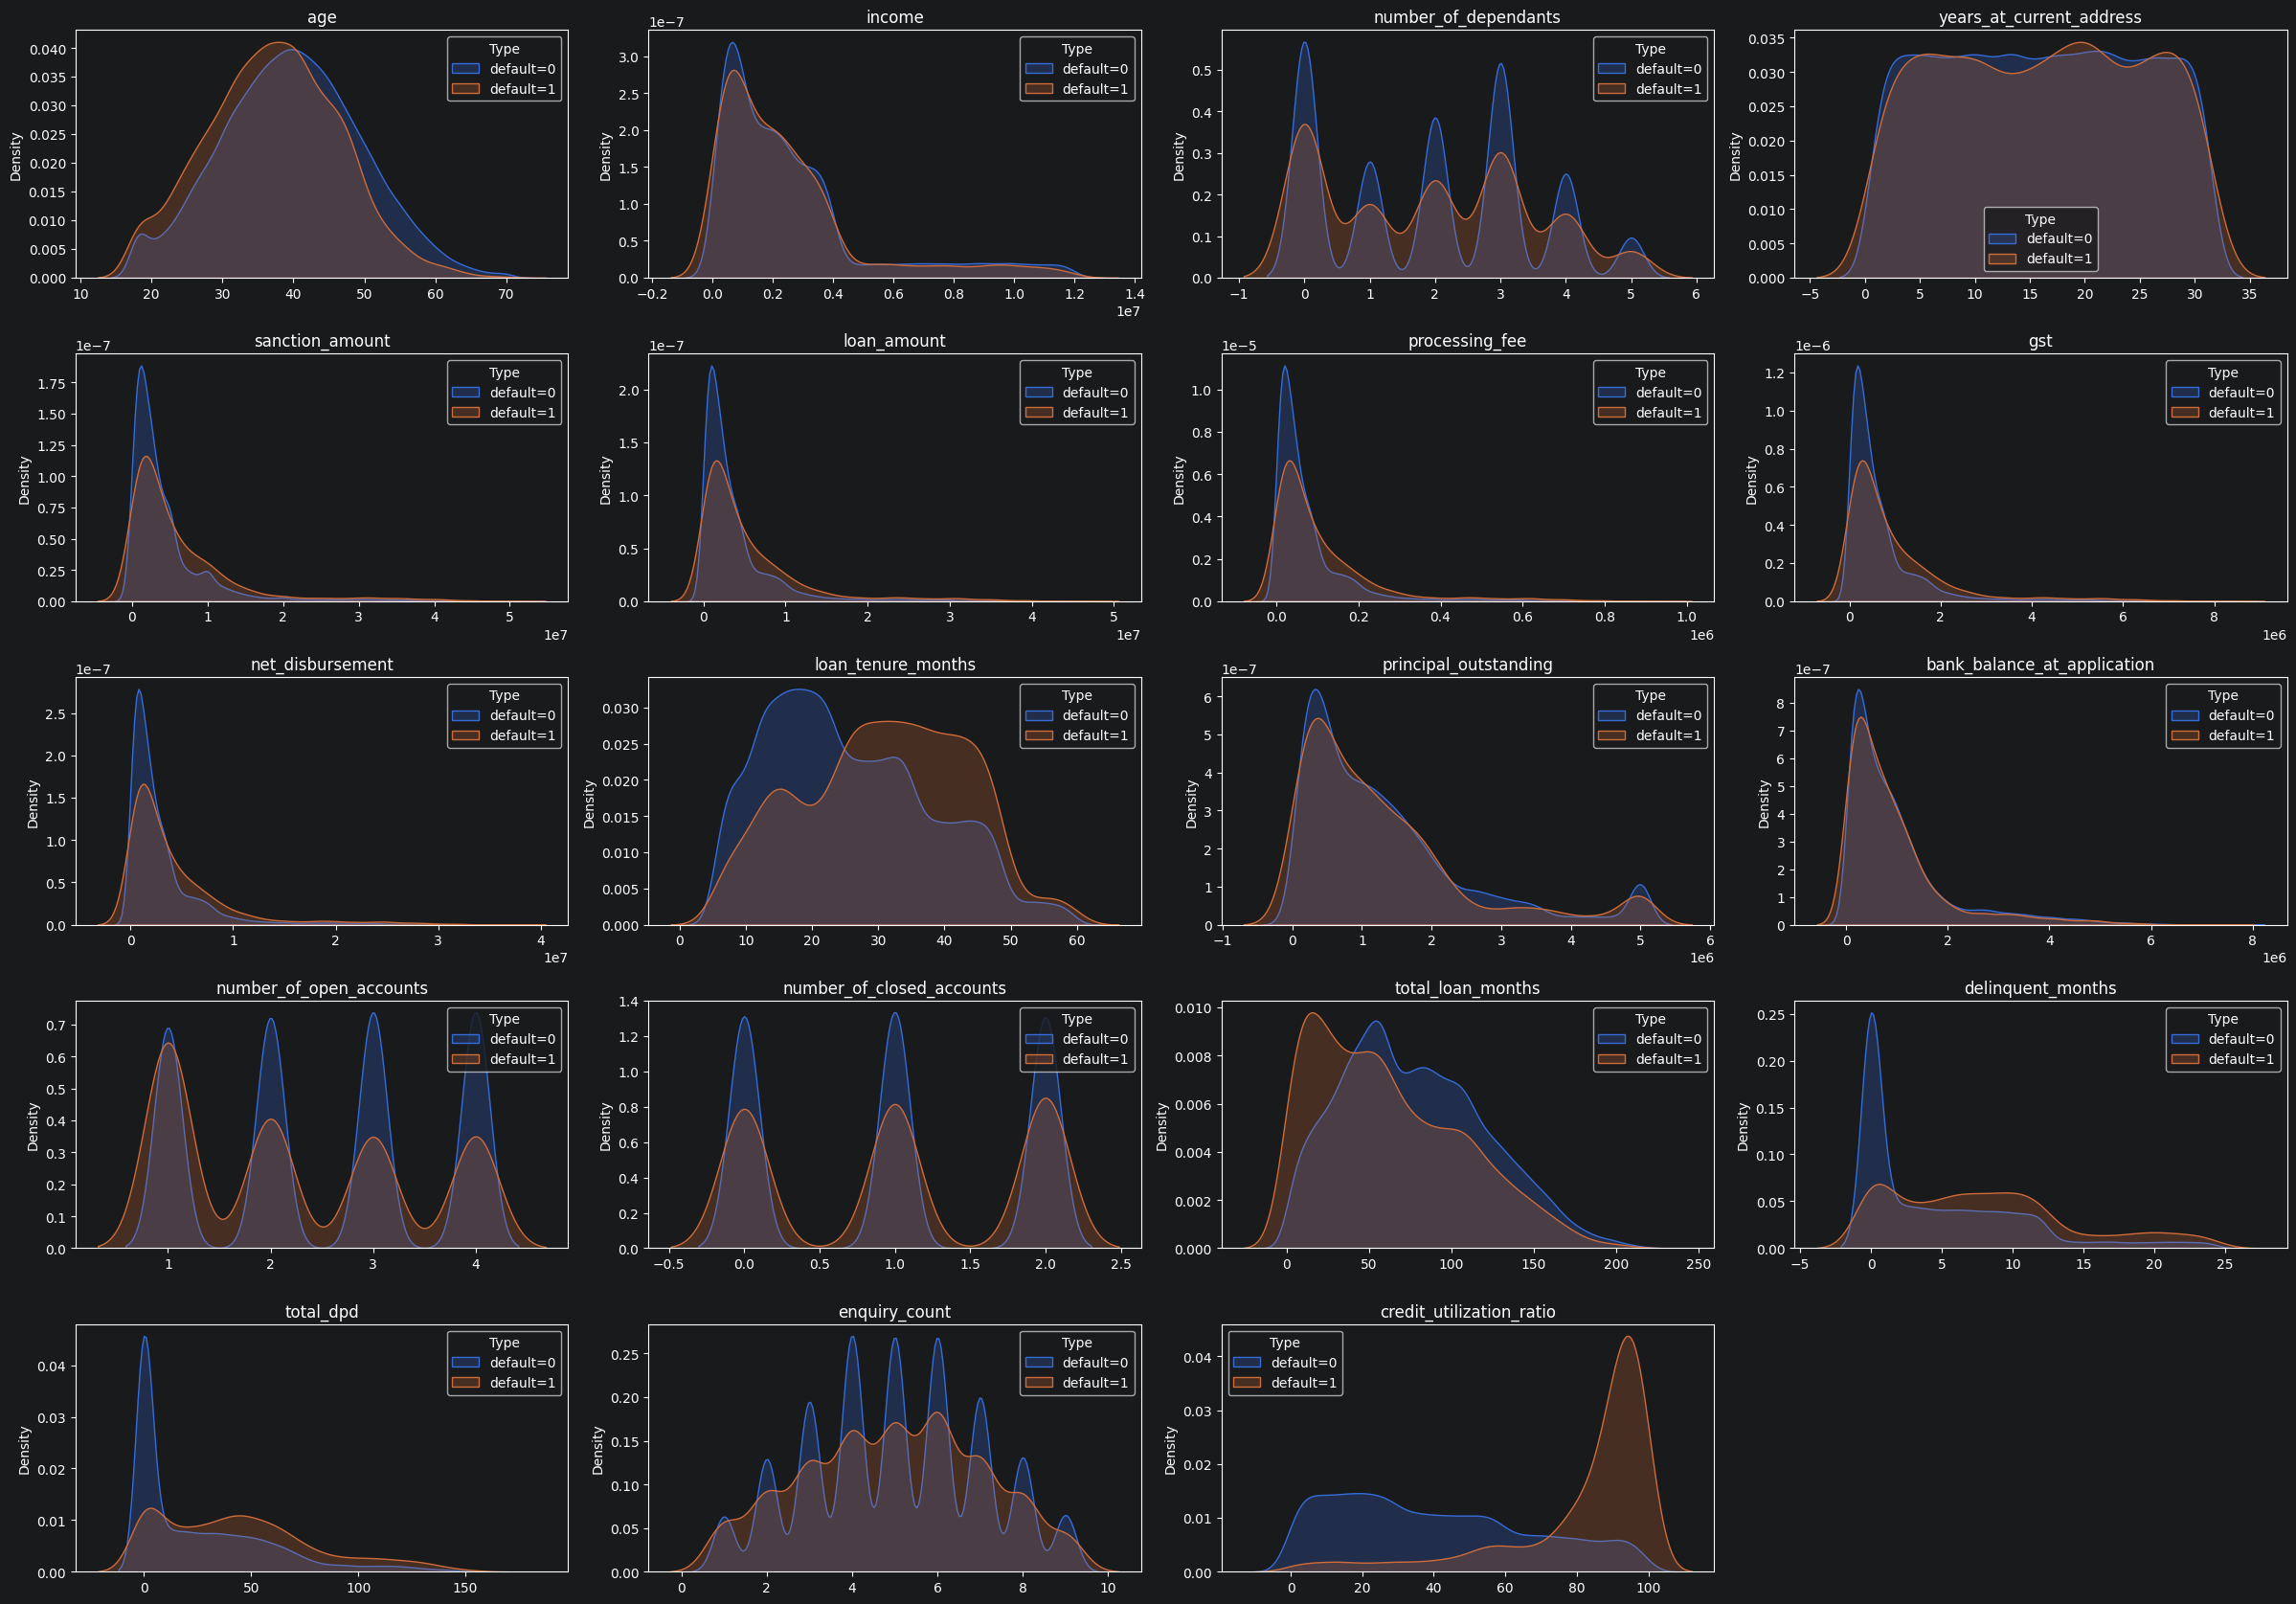

In [97]:
plt.figure(figsize=(24, 20)) # Width, height in inches

for i, col in enumerate(columns_continuous):
    plt.subplot(6, 4, i+1) # 1 row, 4 columns, ith subplot
    sns.kdeplot(df_train_1[col][df_train_1['default']==0], fill=True, label='default=0')
    sns.kdeplot(df_train_1[col][df_train_1['default']==1], fill=True, label='default=1')
    plt.legend(title='Type')
    plt.title(col)
    plt.xlabel('')

plt.tight_layout()
plt.show()

Insights

1. In columns: loan_tenure_months, delinquent_months, total_dpd, credit_utilization, higher values indicate high likelyhood of becoming a default. Hence, these 4 looks like strong predictors
2. In remaining columns the distributions do not give any obvious insights
3. Why loan_amount and income did not give any signs of being strong predictors? May be when we combine these two and get loan to income ratio (LTI), that may have influence on the target variable. We will explore more later


<h3 align ='center' style='color:yellow'>Feature Engineering</h3>

In [98]:
df_train_1['loan_to_income'] = round(df_train_1['loan_amount']/df_train_1['income'], 2)
df_test['loan_to_income'] = round(df_test['loan_amount']/df_test['income'], 2)

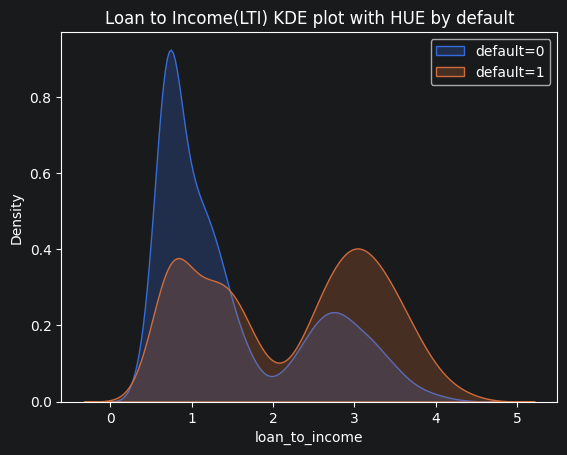

In [99]:
sns.kdeplot(df_train_1[df_train_1['default']==0]['loan_to_income'], fill=True, label='default=0')
sns.kdeplot(df_train_1[df_train_1['default']==1]['loan_to_income'], fill=True, label='default=1')
plt.title(f'Loan to Income(LTI) KDE plot with HUE by default')
plt.legend()
plt.show()

In [100]:
df_train_1.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default',
       'loan_to_income'],
      dtype='object')

In [101]:
df_train_1['delinquency_ratio'] = round(df_train_1['delinquent_months']*100/df_train_1['total_loan_months'], 1)
df_train_1[['delinquent_months', 'total_loan_months', 'delinquency_ratio']].head(3)
df_train_1['delinquency_ratio'].describe()

count   37488.00
mean       10.33
std        17.30
min         0.00
25%         0.00
50%         3.70
75%        12.90
max       100.00
Name: delinquency_ratio, dtype: float64

In [102]:
df_test['delinquency_ratio'] = round(df_test['delinquent_months']*100/df_test['total_loan_months'], 1)

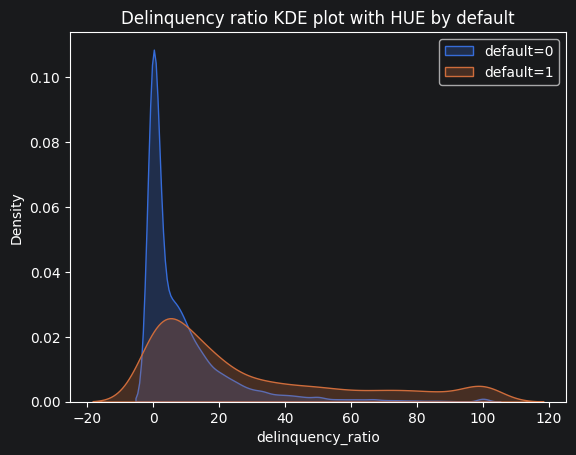

In [103]:
sns.kdeplot(df_train_1[df_train_1['default']==0]['delinquency_ratio'], fill=True, label='default=0')
sns.kdeplot(df_train_1[df_train_1['default']==1]['delinquency_ratio'], fill=True, label='default=1')
plt.title(f'Delinquency ratio KDE plot with HUE by default')
plt.legend()
plt.show()

In [104]:
df_train_1['avg_dpd_per_delinquency'] = np.where(
    df_train_1['delinquent_months']!=0,
    round(df_train_1['total_dpd']/df_train_1['delinquent_months'], 1),
    0)
df_train_1[['total_dpd', 'delinquent_months', 'avg_dpd_per_delinquency']].head(3)
df_train_1['avg_dpd_per_delinquency'].describe()

count   37488.00
mean        3.28
std         2.91
min         0.00
25%         0.00
50%         4.30
75%         5.72
max        10.00
Name: avg_dpd_per_delinquency, dtype: float64

In [105]:
df_test['avg_dpd_per_delinquency'] = np.where(
    df_test['delinquent_months']!=0,
    round(df_test['total_dpd']/df_test['delinquent_months'], 1),
    0)

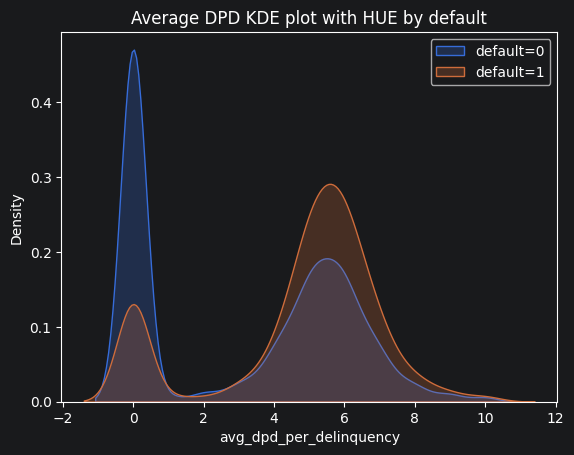

In [106]:
sns.kdeplot(df_train_1[df_train_1['default']==0]['avg_dpd_per_delinquency'], fill=True, label='default=0')
sns.kdeplot(df_train_1[df_train_1['default']==1]['avg_dpd_per_delinquency'], fill=True, label='default=1')
plt.title(f'Average DPD KDE plot with HUE by default')
plt.legend()
plt.show()

### New Feature added: credit_utilization_per_income

In [107]:
df_train_1['credit_utilization_per_income'] = df_train_1['credit_utilization_ratio'] / df_train_1['loan_to_income']

In [108]:
df_test['credit_utilization_per_income'] = df_test['credit_utilization_ratio'] / df_test['loan_to_income']

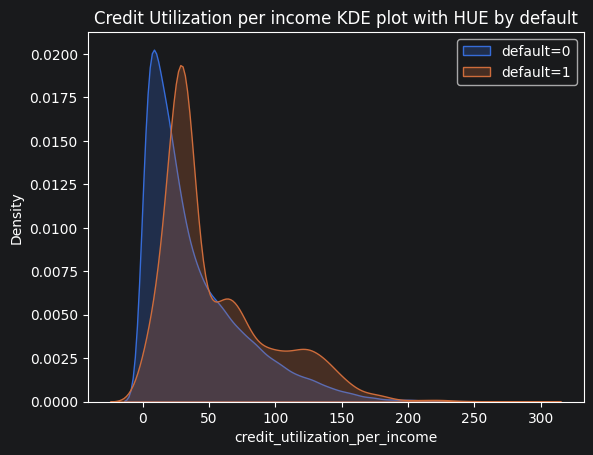

In [109]:
sns.kdeplot(df_train_1[df_train_1['default']==0]['credit_utilization_per_income'], fill=True, label='default=0')
sns.kdeplot(df_train_1[df_train_1['default']==1]['credit_utilization_per_income'], fill=True, label='default=1')
plt.title(f'Credit Utilization per income KDE plot with HUE by default')
plt.legend()
plt.show()

In [110]:
df_train_1.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default',
       'loan_to_income', 'delinquency_ratio', 'avg_dpd_per_delinquency',
       'credit_utilization_per_income'],
      dtype='object')

<h3 align ='center' style='color:yellow'>Feature Selection</h3>

In [111]:
df_train_2 = df_train_1.drop(['cust_id', 'loan_id'], axis=1).copy()
df_test = df_test.drop(['cust_id', 'loan_id'], axis=1)

In [112]:
df_train_3 = df_train_2.drop(['disbursal_date', 'installment_start_dt', 'loan_amount', 'income',
                            'total_loan_months', 'delinquent_months', 'total_dpd'], axis=1)
df_test = df_test.drop(['disbursal_date', 'installment_start_dt', 'loan_amount', 'income',
                        'total_loan_months', 'delinquent_months', 'total_dpd'], axis=1)


In [113]:
df_train_3.info()

<class 'pandas.core.frame.DataFrame'>
Index: 37488 entries, 12746 to 37784
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   age                            37488 non-null  int64  
 1   gender                         37488 non-null  object 
 2   marital_status                 37488 non-null  object 
 3   employment_status              37488 non-null  object 
 4   number_of_dependants           37488 non-null  int64  
 5   residence_type                 37488 non-null  object 
 6   years_at_current_address       37488 non-null  int64  
 7   city                           37488 non-null  object 
 8   state                          37488 non-null  object 
 9   zipcode                        37488 non-null  int64  
 10  loan_purpose                   37488 non-null  object 
 11  loan_type                      37488 non-null  object 
 12  sanction_amount                37488 non-null  

In [114]:
cols_to_scale = df_train_3.select_dtypes(['int64', 'float64'])
cols_to_scale = cols_to_scale.drop(['default', 'zipcode'], axis=1).columns
cols_to_scale

Index(['age', 'number_of_dependants', 'years_at_current_address',
       'sanction_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'credit_utilization_per_income'],
      dtype='object')

In [115]:
X_train = df_train_3.drop('default', axis=1)
y_train = df_train_3['default']

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_train.describe()

,age,number_of_dependants,years_at_current_address,zipcode,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,credit_utilization_per_income
count,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00,37488.00
mean,0.41,0.39,0.50,418876.24,0.09,0.08,0.08,0.08,0.38,0.26,0.12,0.50,0.50,0.50,0.44,0.29,0.10,0.33,0.14
std,0.19,0.31,0.30,169029.87,0.12,0.11,0.11,0.11,0.23,0.24,0.13,0.37,0.41,0.25,0.30,0.23,0.17,0.29,0.13
min,0.00,0.00,0.00,110001.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.29,0.00,0.23,302001.00,0.02,0.02,0.02,0.02,0.19,0.08,0.03,0.00,0.00,0.38,0.18,0.11,0.00,0.00,0.04
50%,0.40,0.40,0.50,400001.00,0.05,0.05,0.05,0.05,0.34,0.19,0.08,0.67,0.50,0.50,0.39,0.20,0.04,0.43,0.09
75%,0.54,0.60,0.77,560001.00,0.10,0.10,0.10,0.10,0.55,0.35,0.16,1.00,1.00,0.62,0.68,0.51,0.13,0.57,0.20
max,1.00,1.00,1.00,700001.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [116]:
X_test = df_test.drop('default', axis=1)
y_test = df_test['default']

X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])
X_test.describe()

,age,number_of_dependants,years_at_current_address,zipcode,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,credit_utilization_per_income
count,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00,12497.00
mean,0.42,0.38,0.50,419759.82,0.09,0.08,0.08,0.08,0.38,0.26,0.12,0.50,0.50,0.50,0.44,0.29,0.11,0.33,0.14
std,0.19,0.31,0.30,168845.35,0.12,0.11,0.11,0.11,0.23,0.25,0.13,0.37,0.41,0.25,0.30,0.23,0.17,0.29,0.13
min,0.00,0.00,0.00,110001.00,-0.00,-0.00,-0.00,-0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.29,0.00,0.23,302001.00,0.02,0.02,0.02,0.02,0.19,0.08,0.03,0.00,0.00,0.38,0.18,0.11,0.00,0.00,0.04
50%,0.42,0.40,0.50,411001.00,0.05,0.05,0.05,0.05,0.34,0.20,0.08,0.33,0.50,0.50,0.39,0.20,0.04,0.44,0.09
75%,0.54,0.60,0.77,560001.00,0.10,0.09,0.09,0.09,0.55,0.36,0.16,0.67,1.00,0.62,0.68,0.50,0.13,0.58,0.20
max,1.00,1.00,1.00,700001.00,0.98,0.96,0.96,0.96,1.00,1.00,0.94,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.96


In [117]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    vif_df = pd.DataFrame()
    vif_df['Variable'] = data.columns
    vif_df['VIF'] = [variance_inflation_factor(data.values, i) for i in range(data.shape[1])]
    return vif_df

In [118]:
calculate_vif(X_train[cols_to_scale])

F:\PyCharm 2025.1.2\projects\.venv\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,Variable,VIF
0,age,5.81
1,number_of_dependants,2.73
2,years_at_current_address,3.39
3,sanction_amount,101.15
4,processing_fee,inf
5,gst,inf
6,net_disbursement,inf
7,loan_tenure_months,6.33
8,principal_outstanding,16.64
9,bank_balance_at_application,10.15


In [119]:
features_to_drop_vif = ['sanction_amount', 'processing_fee', 'gst', 'net_disbursement', 'principal_outstanding']
X_train_1 = X_train.drop(features_to_drop_vif, axis=1)
numeric_columns = X_train_1.select_dtypes(['int64', 'float64']).columns
numeric_columns

Index(['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'loan_tenure_months', 'bank_balance_at_application',
       'number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'credit_utilization_per_income'],
      dtype='object')

In [120]:
vif_df = calculate_vif(X_train_1[numeric_columns])
vif_df

,Variable,VIF
0,age,5.69
1,number_of_dependants,2.73
2,years_at_current_address,3.47
3,zipcode,5.69
4,loan_tenure_months,6.23
5,bank_balance_at_application,1.89
6,number_of_open_accounts,4.36
7,number_of_closed_accounts,2.39
8,enquiry_count,6.47
9,credit_utilization_ratio,10.13


In [121]:
selected_numeric_features_vif = vif_df.Variable.values
selected_numeric_features_vif

array(['age', 'number_of_dependants', 'years_at_current_address',
       'zipcode', 'loan_tenure_months', 'bank_balance_at_application',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'enquiry_count', 'credit_utilization_ratio', 'loan_to_income',
       'delinquency_ratio', 'avg_dpd_per_delinquency',
       'credit_utilization_per_income'], dtype=object)

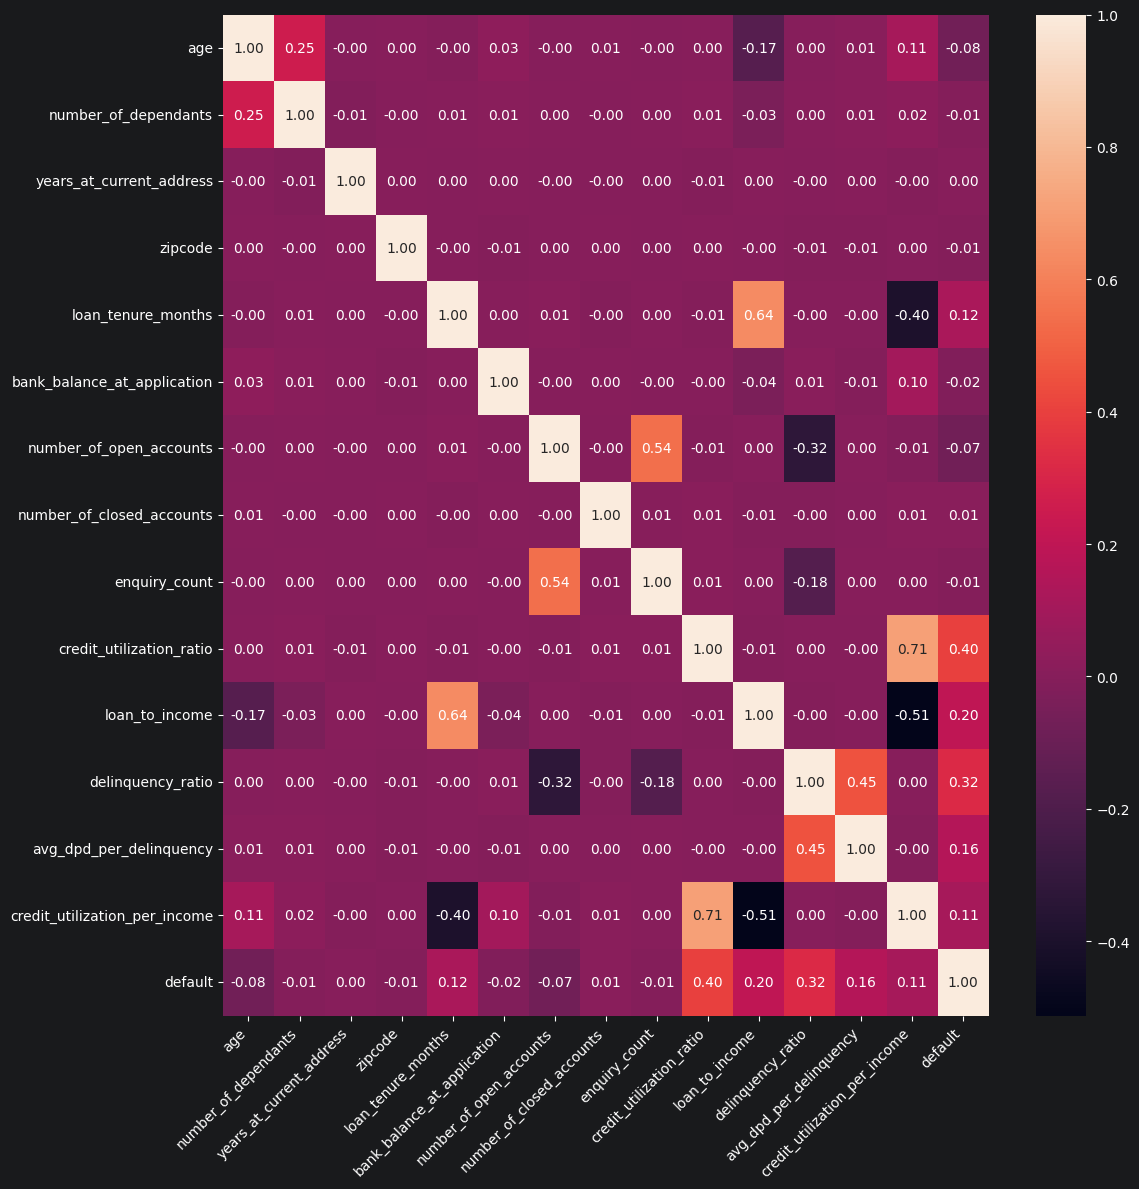

In [122]:
plt.figure(figsize=(12,12))
cm = df_train_3[numeric_columns.append(pd.Index(['default']))].corr()
sns.heatmap(cm, annot=True, fmt='0.2f')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [123]:
columns_categorical

['gender',
 'marital_status',
 'employment_status',
 'residence_type',
 'city',
 'state',
 'zipcode',
 'loan_purpose',
 'loan_type',
 'default']

In [124]:
def calculate_woe_iv(df, feature, target):
    grouped = df.groupby(feature)[target].agg(['count', 'sum'])
    grouped = grouped.rename(columns={'count':'total', 'sum':'good'})
    grouped['bad'] = grouped['total'] - grouped['good']

    total_good = grouped['good'].sum()
    total_bad = grouped['bad'].sum()

    grouped['good_pct'] = grouped['good']/ total_good
    grouped['bad_pct'] = grouped['bad']/ total_bad
    grouped['woe'] = np.log(grouped['good_pct']/grouped['bad_pct'])
    grouped['iv'] = grouped['woe'] * (grouped['good_pct'] - grouped['bad_pct'])

    grouped['woe'] = grouped['woe'].replace([np.inf, -np.inf], 0)
    grouped['iv'] = grouped['iv'].replace([np.inf, -np.inf], 0)

    total_iv = grouped['iv'].sum()
    return grouped, total_iv

grouped, total_iv = calculate_woe_iv(pd.concat([X_train_1, y_train], axis=1), 'loan_purpose', 'default')
grouped

,total,good,bad,good_pct,bad_pct,woe,iv
loan_purpose,,,,,,,
Auto,7447,327,7120,0.10,0.21,-0.72,0.08
Education,5620,559,5061,0.17,0.15,0.16,0.00
Home,11304,1734,9570,0.54,0.28,0.66,0.17
Personal,13117,603,12514,0.19,0.37,-0.67,0.12


In [125]:
iv_values = {}

for feature in X_train_1.columns:
    if X_train_1[feature].dtype == 'object':
        _, iv = calculate_woe_iv(pd.concat([X_train_1, y_train], axis=1), feature, 'default')
    else:
        X_binned = pd.cut(X_train_1[feature], bins=10, labels=False)
        _, iv = calculate_woe_iv(pd.concat([X_binned, y_train], axis=1), feature, 'default')
    iv_values[feature] = iv

iv_values

{'age': np.float64(0.0890689462679479),
 'gender': np.float64(0.00047449502170914947),
 'marital_status': np.float64(0.001129766845390142),
 'employment_status': np.float64(0.003953046301722585),
 'number_of_dependants': np.float64(0.0019380899135053508),
 'residence_type': np.float64(0.246745268718145),
 'years_at_current_address': np.float64(0.0020800513608156363),
 'city': np.float64(0.0019059578709781529),
 'state': np.float64(0.0019005589806779287),
 'zipcode': np.float64(0.0016677413243392572),
 'loan_purpose': np.float64(0.3691197842282755),
 'loan_type': np.float64(0.16319324904149224),
 'loan_tenure_months': np.float64(0.21893515090196278),
 'bank_balance_at_application': np.float64(0.0063187993277516365),
 'number_of_open_accounts': np.float64(0.08463134083005877),
 'number_of_closed_accounts': np.float64(0.0011964272592421567),
 'enquiry_count': np.float64(0.007864214085342608),
 'credit_utilization_ratio': np.float64(2.352965568168245),
 'loan_to_income': np.float64(0.47641

In [126]:
pd.set_option('display.float_format', lambda x: '{:.3f}'.format(x))

iv_df = pd.DataFrame(list(iv_values.items()), columns=['Feature', 'IV'])
iv_df = iv_df.sort_values(by='IV', ascending=False)
iv_df

,Feature,IV
17,credit_utilization_ratio,2.353
19,delinquency_ratio,0.717
18,loan_to_income,0.476
20,avg_dpd_per_delinquency,0.402
10,loan_purpose,0.369
5,residence_type,0.247
12,loan_tenure_months,0.219
21,credit_utilization_per_income,0.196
11,loan_type,0.163
0,age,0.089


In [127]:
selected_features_iv = [feature for feature, iv in iv_values.items() if iv > 0.02]
selected_features_iv

['age',
 'residence_type',
 'loan_purpose',
 'loan_type',
 'loan_tenure_months',
 'number_of_open_accounts',
 'credit_utilization_ratio',
 'loan_to_income',
 'delinquency_ratio',
 'avg_dpd_per_delinquency',
 'credit_utilization_per_income']

<h3 align ='center' style='color:yellow'>Feature Encoding</h3>

In [128]:
X_train_reduced = X_train_1[selected_features_iv]
X_test_reduced = X_test[selected_features_iv]

In [129]:
X_train_reduced.head()

,age,residence_type,loan_purpose,loan_type,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,credit_utilization_per_income
12746,0.788,Owned,Home,Secured,0.415,1.000,0.364,0.415,0.132,0.590,0.060
32495,0.500,Owned,Education,Secured,0.830,0.667,0.051,0.307,0.062,0.620,0.011
43675,0.385,Mortgage,Home,Secured,0.491,0.000,0.000,0.759,0.222,0.560,0.000
9040,0.462,Mortgage,Education,Secured,0.642,0.667,0.879,0.194,0.000,0.000,0.264
13077,0.769,Owned,Personal,Unsecured,0.170,0.000,0.717,0.047,0.000,0.000,0.488


In [130]:
X_train_encoded = pd.get_dummies(X_train_reduced, drop_first=True)
X_test_encoded = pd.get_dummies(X_test_reduced, drop_first=True)

X_train_encoded.head()

,age,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,credit_utilization_per_income,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
12746,0.788,0.415,1.000,0.364,0.415,0.132,0.590,0.060,True,False,False,True,False,False
32495,0.500,0.830,0.667,0.051,0.307,0.062,0.620,0.011,True,False,True,False,False,False
43675,0.385,0.491,0.000,0.000,0.759,0.222,0.560,0.000,False,False,False,True,False,False
9040,0.462,0.642,0.667,0.879,0.194,0.000,0.000,0.264,False,False,True,False,False,False
13077,0.769,0.170,0.000,0.717,0.047,0.000,0.000,0.488,True,False,False,False,True,True


<h3 align ='center' style='color:yellow'>Model Training</h3>

## Optuna Study:
    1. Logistic Regression, XG Boost & Random Forest
    2. Handle class imbalance by SMOTE Tomek
    3. Parameter tuning using Optuna
    4. ROC & AUC with Gini Coeff

In [131]:
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import roc_curve, auc, classification_report
from imblearn.combine import SMOTETomek
from imblearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import make_scorer, f1_score
import optuna
import numpy as np

1. Logistic Regression

In [71]:
def objective_log(trial):
    param = {
        'C': trial.suggest_float('C', 1e-4, 1e4, log=True),
        'solver': trial.suggest_categorical('solver', ['lbfgs', 'liblinear', 'saga', 'newton-cg']),
        'tol': trial.suggest_float('tol', 1e-6, 1e-1, log=True),
        'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced'])
    }

    # SMOTETomek runs strictly on the training splits inside each CV fold
    log_pipeline = Pipeline([
        ('smote_tmk', SMOTETomek(random_state=42)),
        ('logistic', LogisticRegression(**param, max_iter=10000))
    ])

    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    f1_scorer = make_scorer(f1_score, average='macro')
    scores_log = cross_val_score(log_pipeline, X_train_encoded, y_train, cv=cv, scoring=f1_scorer, n_jobs=-1)

    return np.mean(scores_log)

study_logistic = optuna.create_study(direction='maximize')
study_logistic.optimize(objective_log, n_trials=50)

[I 2026-11-17 17:22:34,282] A new study created in memory with name: no-name-42cf45c1-308b-49bc-9145-63eb67306ea4
[I 2026-11-17 17:22:42,150] Trial 0 finished with value: 0.8301697666338296 and parameters: {'C': 63.77933657819457, 'solver': 'liblinear', 'tol': 1.1718937994831233e-06, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.8301697666338296.
[I 2026-11-17 17:22:48,423] Trial 1 finished with value: 0.6671113881465137 and parameters: {'C': 0.06806249052084795, 'solver': 'newton-cg', 'tol': 0.09226072980723028, 'class_weight': None}. Best is trial 0 with value: 0.8301697666338296.
[I 2026-11-17 17:22:54,462] Trial 2 finished with value: 0.7647852006505214 and parameters: {'C': 0.005961995209845337, 'solver': 'newton-cg', 'tol': 0.0029499907714981262, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.8301697666338296.
[I 2026-11-17 17:23:00,470] Trial 3 finished with value: 0.8137846520161315 and parameters: {'C': 0.7927995870136254, 'solver': 'liblinear', 'tol':

In [132]:
print('Best trial:')
trial_log = study_logistic.best_trial
print('  F1-score: {}'.format(trial_log.value))
print('  Params: ')
for key, value in trial_log.params.items():
    print('    {}: {}'.format(key, value))

best_log_pipeline = Pipeline([
    ('smote_tmk', SMOTETomek(random_state=42)),
    ('logistic', LogisticRegression(**study_logistic.best_params))
])
best_log_pipeline.fit(X_train_encoded, y_train)

# Evaluate on the test set
y_pred_log = best_log_pipeline.predict(X_test_encoded)

report_log = classification_report(y_test, y_pred_log)
print('Classification Report for Logistic Regression Classifier:')
print(report_log)

Best trial:
  F1-score: 0.8334005315916851
  Params: 
    C: 2813.5478662437895
    solver: saga
    tol: 0.09842005874939669
    class_weight: None
Classification Report for Logistic Regression Classifier:
              precision    recall  f1-score   support

           0       1.00      0.92      0.96     11423
           1       0.54      0.95      0.69      1074

    accuracy                           0.93     12497
   macro avg       0.77      0.94      0.82     12497
weighted avg       0.96      0.93      0.93     12497



In [140]:
probabilities_log = best_log_pipeline.predict_proba(X_test_encoded)[:,1]

fpr_log, tpr_log, thresholds_log = roc_curve(y_test, probabilities_log)

area_log = auc(fpr_log, tpr_log)

gini_coeff_log = 2*area_log -1
print('Logistic Regression AUC and Gini Coefficient:')
print('AUC', area_log)
print('Gini Coefficient', gini_coeff_log)

Logistic Regression AUC and Gini Coefficient:
AUC 0.983399658730279
Gini Coefficient 0.966799317460558


2. XG Boost Classifier

In [134]:
def objective_xgb(trial):
    param = {
        'objective': 'binary:logistic',
        'eval_metric': 'logloss',
        'verbosity': 0,
        'booster': 'gbtree',
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'lambda': trial.suggest_float('lambda', 1e-3, 10.0, log=True),
        'alpha': trial.suggest_float('alpha', 1e-3, 10.0, log=True),
        'subsample': trial.suggest_float('subsample', 0.4, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.4, 1.0),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'eta': trial.suggest_float('eta', 0.01, 0.3, log=True),
        'gamma': trial.suggest_float('gamma', 0, 10),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'max_delta_step': trial.suggest_int('max_delta_step', 0, 10),
        'random_state': 42,
        'n_jobs': -1
    }

    # SMOTE runs strictly on the training splits inside each CV fold
    xgb_pipeline = Pipeline([
        ('smote_tmk', SMOTETomek(random_state=42)),
        ('xgb', XGBClassifier(**param))
    ])

    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    f1_scorer = make_scorer(f1_score, average='macro')

    # Pass original un-resampled X_train and y_train
    scores = cross_val_score(xgb_pipeline, X_train_encoded, y_train, cv=cv, scoring=f1_scorer, n_jobs=1)

    return np.mean(scores)

study_xgb = optuna.create_study(direction='maximize')
study_xgb.optimize(objective_xgb, n_trials=50)

[I 2026-11-17 17:25:41,361] A new study created in memory with name: no-name-1cd9e6d6-1d36-493d-9354-3f3d1372a8b2
[I 2026-11-17 17:25:49,881] Trial 0 finished with value: 0.8707899717935442 and parameters: {'n_estimators': 435, 'lambda': 0.008625804233060582, 'alpha': 0.14316517651540825, 'subsample': 0.5613575711156971, 'colsample_bytree': 0.6202201062694388, 'max_depth': 3, 'eta': 0.07336353032792227, 'gamma': 2.69602529182987, 'min_child_weight': 4, 'max_delta_step': 1}. Best is trial 0 with value: 0.8707899717935442.
[I 2026-11-17 17:25:57,872] Trial 1 finished with value: 0.8176820196954084 and parameters: {'n_estimators': 104, 'lambda': 0.19035086078920624, 'alpha': 0.042585290006757905, 'subsample': 0.994543446919791, 'colsample_bytree': 0.8750245850027891, 'max_depth': 4, 'eta': 0.03448316030735904, 'gamma': 8.416747782444915, 'min_child_weight': 9, 'max_delta_step': 6}. Best is trial 0 with value: 0.8707899717935442.
[I 2026-11-17 17:26:08,581] Trial 2 finished with value: 0.8

In [135]:
print('Best trial:')
trial_xgb = study_xgb.best_trial
print('  F1-score: {}'.format(trial_xgb.value))
print('  Params: ')
for key, value in trial_xgb.params.items():
    print('    {}: {}'.format(key, value))

best_xgb_params = {
    'objective': 'binary:logistic',
    'eval_metric': 'logloss',
    'verbosity': 0,
    'booster': 'gbtree',
    'random_state': 42,
    'n_jobs': -1,
    **study_xgb.best_params
}

best_xgb_pipeline = Pipeline([
    ('smote', SMOTETomek(random_state=42)),
    ('xgb', XGBClassifier(**best_xgb_params))
])
best_xgb_pipeline.fit(X_train_encoded, y_train)

# Evaluate on the test set
y_pred_xgb = best_xgb_pipeline.predict(X_test_encoded)

report_xgb = classification_report(y_test, y_pred_xgb)
print('Classification Report for XG Boost Classifier:')
print(report_xgb)

Best trial:
  F1-score: 0.8794662837917292
  Params: 
    n_estimators: 442
    lambda: 1.3470469303506543
    alpha: 0.052934020997795345
    subsample: 0.5580466172069227
    colsample_bytree: 0.8042949721873265
    max_depth: 4
    eta: 0.17442878911299994
    gamma: 2.747587028048764
    min_child_weight: 8
    max_delta_step: 10
Classification Report for XG Boost Classifier:
              precision    recall  f1-score   support

           0       0.98      0.97      0.98     11423
           1       0.76      0.84      0.80      1074

    accuracy                           0.96     12497
   macro avg       0.87      0.91      0.89     12497
weighted avg       0.97      0.96      0.96     12497



In [141]:
probabilities_xgb = best_xgb_pipeline.predict_proba(X_test_encoded)[:,1]

fpr_xgb, tpr_xgb, thresholds_xgb = roc_curve(y_test, probabilities_xgb)

area_xgb = auc(fpr_xgb, tpr_xgb)

gini_coeff_xgb = 2*area_xgb -1
print('XG Boost AUC and Gini Coefficient:')
print('AUC', area_xgb)
print('Gini Coefficient', gini_coeff_xgb)

XG Boost AUC and Gini Coefficient:
AUC 0.9873072084466131
Gini Coefficient 0.9746144168932263


2. Random Forest Classifier

In [137]:
def objective_rf(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', 5, 30),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features': trial.suggest_float('max_features', 0.2, 1.0),
        'max_samples': trial.suggest_float('max_samples', 0.5, 1.0),
        'criterion': trial.suggest_categorical('criterion', ['gini', 'entropy']),
        'bootstrap': True,
        'random_state': 42,
        'n_jobs': -1
    }

    # Build the pipeline so SMOTE only runs on the training folds
    rf_pipeline = Pipeline([
        ('smote', SMOTETomek(random_state=42)),
        ('rf', RandomForestClassifier(**param))
    ])

    # StratifiedKFold ensures each fold maintains the original class ratio
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    f1_scorer = make_scorer(f1_score, average='macro')

    # Pass the ORIGINAL un-resampled X_train and y_train
    scores = cross_val_score(rf_pipeline, X_train_encoded, y_train, cv=cv, scoring=f1_scorer, n_jobs=1)

    return np.mean(scores)

study_rf = optuna.create_study(direction='maximize')
study_rf.optimize(objective_rf, n_trials=50)

[I 2026-11-17 17:32:27,662] A new study created in memory with name: no-name-bd06fe9b-9b51-48cd-9a39-e057ba7f5a6e
[I 2026-11-17 17:32:42,701] Trial 0 finished with value: 0.837895437059958 and parameters: {'n_estimators': 428, 'max_depth': 10, 'min_samples_split': 19, 'min_samples_leaf': 8, 'max_features': 0.29032891004909134, 'max_samples': 0.5856744833551287, 'criterion': 'entropy'}. Best is trial 0 with value: 0.837895437059958.
[I 2026-11-17 17:32:54,056] Trial 1 finished with value: 0.8593491509590043 and parameters: {'n_estimators': 259, 'max_depth': 18, 'min_samples_split': 3, 'min_samples_leaf': 2, 'max_features': 0.4759776131353755, 'max_samples': 0.5567557344631897, 'criterion': 'gini'}. Best is trial 1 with value: 0.8593491509590043.
[I 2026-11-17 17:33:13,949] Trial 2 finished with value: 0.8560756045071333 and parameters: {'n_estimators': 336, 'max_depth': 20, 'min_samples_split': 8, 'min_samples_leaf': 8, 'max_features': 0.7575836665367297, 'max_samples': 0.95689432239939

In [138]:
best_rf_pipeline = Pipeline([
    ('smote', SMOTETomek(random_state=42)),
    ('rf', RandomForestClassifier(**study_rf.best_params, bootstrap=True, random_state=42, n_jobs=-1))
])
best_rf_pipeline.fit(X_train_encoded, y_train)

# Evaluate on the test set
y_pred_rf = best_xgb_pipeline.predict(X_test_encoded)

report_rf = classification_report(y_test, y_pred_rf)
print('Classification Report for Random Forest Classifier:')
print(report_rf)

Classification Report for Random Forest Classifier:
              precision    recall  f1-score   support

           0       0.98      0.97      0.98     11423
           1       0.76      0.84      0.80      1074

    accuracy                           0.96     12497
   macro avg       0.87      0.91      0.89     12497
weighted avg       0.97      0.96      0.96     12497



In [139]:
rf_probabilities = best_rf_pipeline.predict_proba(X_test_encoded)[:,1]

fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, rf_probabilities)

area_rf = auc(fpr_rf, tpr_rf)

gini_coeff_rf = 2*area_rf -1
print('Random Forest AUC and Gini Coefficient:')
print('AUC', area_rf)
print('Gini Coefficient', gini_coeff_rf)

Random Forest AUC and Gini Coefficient:
AUC 0.9852616931014576
Gini Coefficient 0.9705233862029152


1. credit_utilization_ratio: High values (red) increase the likelihood of default, as shown by positive SHAP values.
2. delinquency_ratio: Similarly, higher values increase the risk, shown by positive SHAP values.
3. loan_to_income: Higher values (red) also increase the default risk.
4. residence_type_Owned and residence_type_Rented: Different impacts based on whether the residence is owned or rented.
5. avg_dpd_per_delinquency: Higher average days past due per delinquency increase the risk.